<a href="https://colab.research.google.com/github/fergonzalvo/ISSD_AA1/blob/main/%F0%9F%A7%A0%F0%9F%8C%90Resoluci%C3%B3n_de_Actividades_Redes_Neuronales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
#CREACION DE ENTORNO
# ── Librerías básicas de datos y gráficos ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

# ── Utilidades de scikit-learn para preparar datos y validar ──
from sklearn.model_selection import (
    train_test_split, cross_val_score, validation_curve,
    GridSearchCV, RandomizedSearchCV, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

# ── Los modelos protagonistas: redes neuronales ──
from sklearn.neural_network import MLPRegressor, MLPClassifier

# ── Modelos de referencia (para comparar) ──
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression

# ── Métricas ──
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
)

# ── Para interpretar un modelo "caja negra" ──
from sklearn.inspection import permutation_importance

# ── Distribución para la búsqueda aleatoria de hiperparámetros ──
from scipy.stats import loguniform

# ── Configuración general ──
SEMILLA = 42                       # Fijamos la semilla para que los resultados sean reproducibles
sns.set_theme(style="whitegrid")   # Estilo de gráficos
pd.set_option("display.precision", 3)

# Las redes neuronales lanzan muchos avisos de "convergencia" cuando entrenamos decenas de modelos
# (por ejemplo, en las búsquedas de hiperparámetros). Para no llenar la pantalla los ocultamos,
# pero en la sección 7.1 los vamos a reactivar a propósito para entender qué significan.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "ignore::sklearn.exceptions.ConvergenceWarning"  # también en procesos paralelos

print("¡Todo listo!")

¡Todo listo!


---
# Parte 5 - Actividades

Ahora es tu turno. **Reutilizá el código de las partes anteriores** (copiar, pegar y adaptar es totalmente válido). Cada actividad indica qué parte del taller te sirve de guía.

> 💡 En las celdas de código encontrarás pistas como comentarios. Las celdas de texto "**Tu respuesta:**" son para que escribas tus conclusiones (doble clic para editar).

## Actividad 1. Regresión: predecir el precio de diamantes

**Dataset:** `diamonds` (público, repositorio de datos de `seaborn`). Cada fila es un diamante con su precio en dólares y características como peso (`carat`), calidad de corte (`cut`), color (`color`), claridad (`clarity`) y dimensiones (`x`, `y`, `z`).

**Objetivo:** predecir `price` con una red neuronal y compararla con modelos de referencia.

**Te sirve de guía:** Parte 2 (Regresión).

Para que los entrenamientos no tarden demasiado, trabajaremos con una **muestra de 3000 diamantes**.

In [13]:
# Cargamos el dataset y tomamos una muestra de 3000 filas
import pandas as pd
url_diamantes = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"
df_diam = pd.read_csv(url_diamantes).sample(n=3000, random_state=42).reset_index(drop=True)

df_diam.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
1,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
2,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
3,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
4,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61


**1.1 · Exploración.** Averiguá: ¿cuántas variables numéricas y categóricas hay? ¿Hay valores faltantes? Graficá la distribución de `price` y la relación entre `carat` y `price`. ¿Notás algo particular en la distribución del precio?

In [14]:
# Tu código aquí
# Pista: df_diam.info(), df_diam.describe(), sns.histplot(...), sns.scatterplot(...)
df_diam.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    3000 non-null   float64
 1   cut      3000 non-null   object 
 2   color    3000 non-null   object 
 3   clarity  3000 non-null   object 
 4   depth    3000 non-null   float64
 5   table    3000 non-null   float64
 6   price    3000 non-null   int64  
 7   x        3000 non-null   float64
 8   y        3000 non-null   float64
 9   z        3000 non-null   float64
dtypes: float64(6), int64(1), object(3)
memory usage: 234.5+ KB


In [15]:
df_diam.describe()

,carat,depth,table,price,x,y,z
count,3000.000,3000.000,3000.000,3000.000,3000.000,3000.000,3000.000
mean,0.803,61.760,57.453,3946.290,5.735,5.735,3.541
std,0.490,1.432,2.288,4083.685,1.149,1.142,0.706
min,0.230,54.400,49.000,358.000,3.880,3.920,2.320
25%,0.390,61.075,56.000,926.750,4.680,4.690,2.890
50%,0.700,61.900,57.000,2352.000,5.690,5.700,3.520
75%,1.040,62.500,59.000,5303.250,6.560,6.560,4.030
max,4.010,69.900,73.000,18823.000,10.020,9.940,6.310


In [16]:
df_diam.isna().sum()

,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
price,0
x,0
y,0
z,0


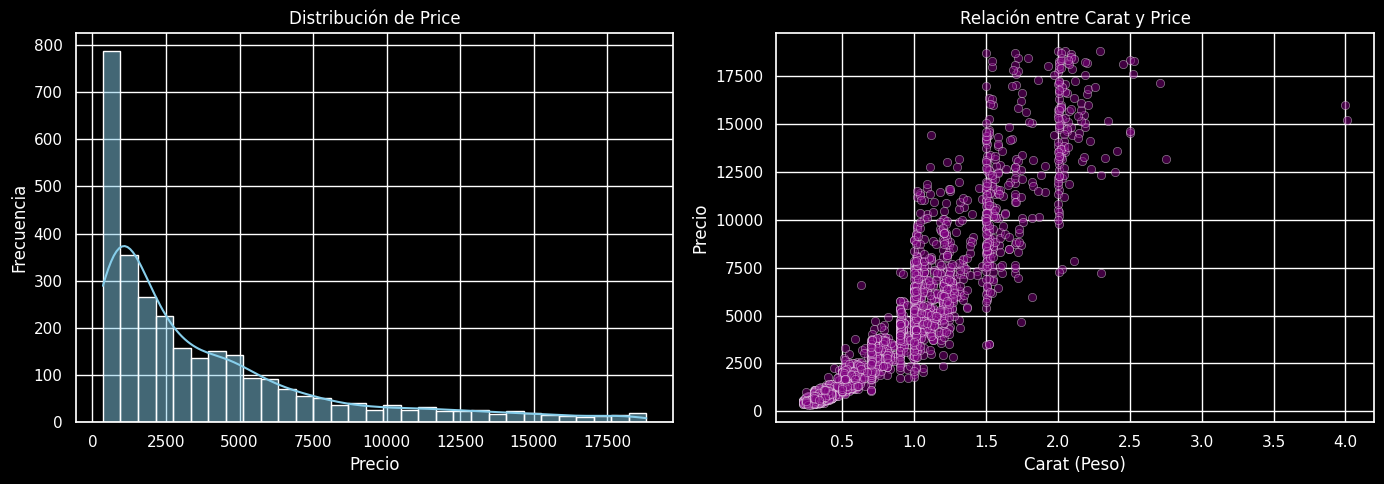

In [17]:
#ia generativa para los gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el estilo de los gráficos
sns.set_theme(style="whitegrid")
plt.style.use('dark_background')

# Figura con dos gráficos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Distribución de price
sns.histplot(df_diam['price'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribución de Price')
axes[0].set_xlabel('Precio')
axes[0].set_ylabel('Frecuencia')

# 2. Relación entre carat y price
sns.scatterplot(data=df_diam, x='carat', y='price', alpha=0.5, ax=axes[1], color='purple')
axes[1].set_title('Relación entre Carat y Price')
axes[1].set_xlabel('Carat (Peso)')
axes[1].set_ylabel('Precio')

plt.tight_layout()
plt.show()

**Tu respuesta (1.1):**

*(escribí acá tus observaciones)*

Variables categóricas (3): cut, color, clarity (tipo texto/object).

Variables numéricas (7): carat, depth, table, price, x, y, z (tipo float o int).

**1.2 · División y preprocesamiento.**
- Separá `X` (todo menos `price`) e `y` (`price`).
- Dividí en entrenamiento (80 %) y prueba (20 %).
- Armá un `ColumnTransformer` que estandarice las numéricas y aplique `OneHotEncoder` a `cut`, `color` y `clarity`.

In [18]:
# Tu código aquí
# Separamos predictoras (X) y objetivo (y)
X = df_diam.drop(columns=["price"])
y = df_diam["price"]

# Dividimos en entrenamiento y prueba
X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)

print(f"Entrenamiento: {X_ent.shape[0]} diamantes")
print(f"Prueba:        {X_prueba.shape[0]} diamante")
# Pista: mirá el "Paso 1" y el "Paso 2" de la Parte 2.


# cols_num_d = [...]
# cols_cat_d = [...]
# Separamos las columnas según su tipo

cols_num = ["carat", "depth", "table", "x", "y", "z"]
cols_cat = ["cut", "color", "clarity"]

# Preprocesador: qué hacerle a cada grupo de columnas
preprocesador_reg = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),   # rellena faltantes con la mediana
        ("escalar", StandardScaler())                    # media 0, desvío 1
    ]), cols_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cols_cat)  # categorías -> columnas 0/1
])

preprocesador_reg

Entrenamiento: 2400 diamantes
Prueba:        600 diamante


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalar',
                                                  StandardScaler())]),
                                 ['carat', 'depth', 'table', 'x', 'y', 'z']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['cut', 'color', 'clarity'])])

**1.3 · Modelos de referencia.** Entrená un `DummyRegressor` y una `LinearRegression`, y guardá sus métricas (RMSE, MAE, R²) en una lista de resultados usando la función `evaluar_regresion` que ya definimos.

In [19]:
#funcion evaluadora(guardar)
def evaluar_regresion(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):
    pred_ent = modelo.predict(X_ent)
    pred_prueba = modelo.predict(X_prueba)
    return {
        "modelo": nombre,
        "RMSE_entrenamiento": root_mean_squared_error(y_ent, pred_ent),
        "RMSE_prueba": root_mean_squared_error(y_prueba, pred_prueba),
        "MAE_prueba": mean_absolute_error(y_prueba, pred_prueba),
        "R2_prueba": r2_score(y_prueba, pred_prueba),
    }

# Aquí iremos guardando los resultados de cada modelo para compararlos al final
resultados_reg = []

In [20]:
resultados_reg = []

In [21]:
# Tu código aquí
# Pista: resultados_diam = []  y luego resultados_diam.append(evaluar_regresion(...))
# Baseline 1: predice siempre el promedio
modelo_dummy = DummyRegressor(strategy="mean")
modelo_dummy.fit(X_ent[cols_num], y_ent)
resultados_reg.append(evaluar_regresion(modelo_dummy, X_ent[cols_num], y_ent, X_prueba[cols_num], y_prueba, "Dummy (promedio)"))

# Baseline 2: regresión lineal (dentro de un Pipeline con el mismo preprocesador)
modelo_lineal = Pipeline([
    ("prep", preprocesador_reg),
    ("modelo", LinearRegression())
])
modelo_lineal.fit(X_ent, y_ent)
resultados_reg.append(evaluar_regresion(modelo_lineal, X_ent, y_ent, X_prueba, y_prueba, "Regresión lineal"))

pd.DataFrame(resultados_reg)

,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),4040.451,4249.481,3220.319,-0.001
1,Regresión lineal,1138.336,1106.483,730.659,0.932


**1.4 · Primera red neuronal.** Entrená un `MLPRegressor` con `hidden_layer_sizes=(64, 32)` dentro de un `Pipeline`. Evaluá en entrenamiento y prueba. Graficá **real vs. predicho** y la **curva de pérdida**. ¿Le gana a la regresión lineal?

In [22]:
# Tu código aquí
# Pista: Paso 4 y Paso 5 de la Parte 2.
# Definimos la red neuronal dentro de un Pipeline
mlp_reg = Pipeline([
    ("prep", preprocesador_reg),#resultado del column transformer
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(64, 32),   # 2 capas ocultas: 64 y 32 neuronas
        activation="relu",             # función de activación
        max_iter=500,                 # máximo de épocas
        random_state=SEMILLA           # para reproducibilidad
    ))
])

# Entrenamos ("fit") con los datos de entrenamiento
mlp_reg.fit(X_ent, y_ent)

# ¿Cuántas épocas usó realmente la red? (si es igual a max_iter, llegó al límite)
print("Épocas realizadas:", mlp_reg.named_steps["mlp"].n_iter_)

# Evaluamos y guardamos resultados
resultados_reg.append(evaluar_regresion(mlp_reg, X_ent, y_ent, X_prueba, y_prueba, "MLP inicial (64,32)"))
pd.DataFrame(resultados_reg)

Épocas realizadas: 500


,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),4040.451,4249.481,3220.319,-0.001
1,Regresión lineal,1138.336,1106.483,730.659,0.932
2,"MLP inicial (64,32)",744.876,768.426,394.444,0.967


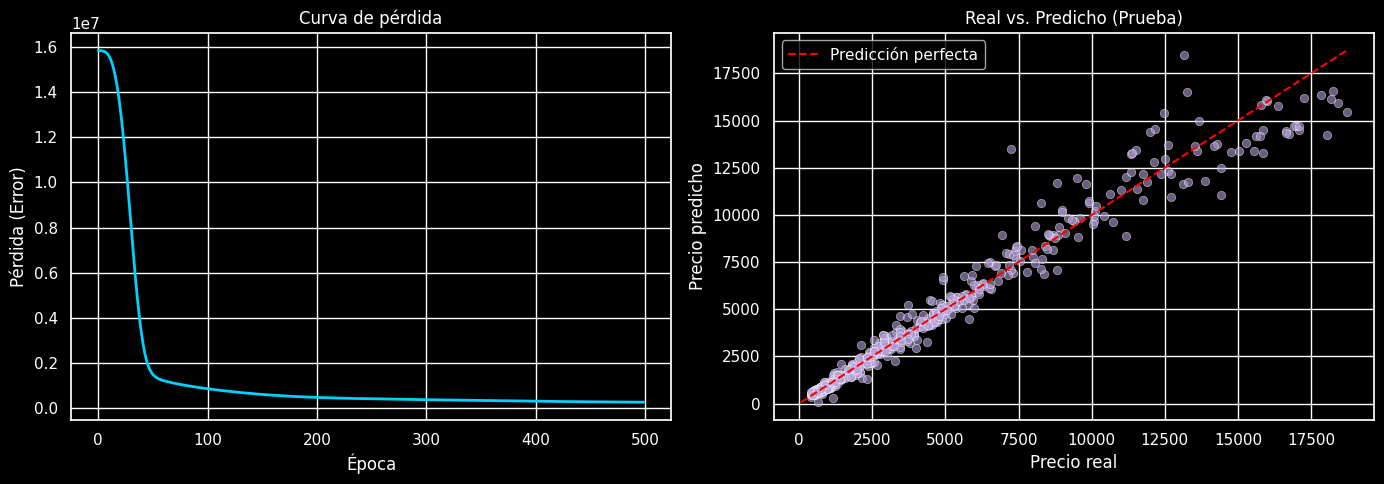

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Activar modo oscuro para los gráficos
plt.style.use('dark_background')

# 1. Obtener las predicciones en el conjunto de prueba
# (Ajustá 'modelo_mlp' al nombre exacto de tu variable o pipeline)
y_pred =mlp_reg.predict(X_prueba)

# Figura con los dos gráficos requeridos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Gráfico 1: Curva de pérdida (loss_curve_ de scikit-learn MLPRegressor) ---
# Si tu modelo está dentro de un Pipeline, accedé al paso del mlp, ej: modelo_mlp.named_steps['modelo'].loss_curve_
# Si entrenaste el MLPRegressor directamente sin pipeline, usá modelo_mlp.loss_curve_
loss_values = mlp_reg.named_steps['mlp'].loss_curve_ if hasattr(mlp_reg, 'named_steps') else mlp_reg.loss_curve_

axes[0].plot(loss_values, color='#00d2ff', linewidth=2)
axes[0].set_title('Curva de pérdida', color='white')
axes[0].set_xlabel('Época', color='white')
axes[0].set_ylabel('Pérdida (Error)', color='white')

# --- Gráfico 2: Real vs. Predicho ---
sns.scatterplot(x=y_prueba, y=y_pred, ax=axes[1], alpha=0.6, color='#b19cd9')
# Línea de predicción perfecta (y = x)
lims = [min(min(y_prueba), min(y_pred)), max(max(y_prueba), max(y_pred))]
axes[1].plot(lims, lims, '--', color='red', label='Predicción perfecta')

axes[1].set_title('Real vs. Predicho (Prueba)', color='white')
axes[1].set_xlabel('Precio real', color='white')
axes[1].set_ylabel('Precio predicho', color='white')
axes[1].legend()

plt.tight_layout()
plt.show()

##Conclusión:
el rmse baja a la mitad, se mantiene en la prueba y aumenta el porcentaje de datos explicados por el model

**1.5 · Ajuste de hiperparámetros.** Usá `GridSearchCV` o `RandomizedSearchCV` (a tu elección) con validación cruzada de 5 particiones para explorar al menos **3 hiperparámetros** (por ejemplo `hidden_layer_sizes`, `alpha`, `learning_rate_init`). Mostrá los 5 mejores resultados y evaluá el mejor modelo en el conjunto de prueba.

⏱️ *Cuidado con el tiempo de ejecución: empezá con una grilla chica.*

In [24]:
# Tu código aquí
# Pista: Paso 8 y Paso 9 de la Parte 2 (o Paso 4 de la Parte 3 para RandomizedSearchCV).
# Grilla de hiperparámetros a explorar
grilla_reg = {
    "mlp__hidden_layer_sizes":  [(4,),(8,),(16,)],   # arquitecturas
    "mlp__alpha": [0.0001, 0.01, 1.0],                     # regularización
    "mlp__learning_rate_init": [0.001, 0.01],              # tamaño de paso
}

busqueda_reg = GridSearchCV(
    estimator=mlp_reg,
    param_grid=grilla_reg,
    cv=5,                                     # validación cruzada de 5 particiones
    scoring="neg_root_mean_squared_error",    # sklearn maximiza: usamos -RMSE
    n_jobs=-1,                                # usa todos los núcleos disponibles
    verbose=1
)

busqueda_reg.fit(X_ent, y_ent)

print("\nMejores hiperparámetros:")
print(busqueda_reg.best_params_)
print(f"\nMejor RMSE en validación cruzada: {-busqueda_reg.best_score_:.3f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Mejores hiperparámetros:
{'mlp__alpha': 1.0, 'mlp__hidden_layer_sizes': (16,), 'mlp__learning_rate_init': 0.01}

Mejor RMSE en validación cruzada: 913.230


In [25]:
import pandas as pd

# Convertimos los resultados de GridSearchCV en un DataFrame
resultados_cv = pd.DataFrame(busqueda_reg.cv_results_)

# Ordenamos por mejor puntaje (recordá que el score es negativo por ser -RMSE, por lo que ordenamos de mayor a menor)
top_5 = resultados_cv.sort_values(by="mean_test_score", ascending=False).head(5)

# Seleccionamos y mostramos las columnas más importantes del Top 5
columnas_interes = [ 'rank_test_score','param_mlp__hidden_layer_sizes', 'param_mlp__alpha', 'param_mlp__learning_rate_init', 'mean_test_score']
print("Top 5 mejores combinaciones de hiperparámetros:")
display(top_5[columnas_interes])

Top 5 mejores combinaciones de hiperparámetros:


,rank_test_score,param_mlp__hidden_layer_sizes,param_mlp__alpha,param_mlp__learning_rate_init,mean_test_score
17,1,"(16,)",1.000e+00,0.01,-913.230
5,2,"(16,)",1.000e-04,0.01,-919.251
11,3,"(16,)",1.000e-02,0.01,-919.293
3,4,"(8,)",1.000e-04,0.01,-970.673
9,5,"(8,)",1.000e-02,0.01,-970.697


mostramos los 5 mejores valores de CV, aclaramos que el rmse se muestra en negativo por un proceso interno de scikitlear.

In [26]:
#evaluacion final con cv
mejor_reg = busqueda_reg.best_estimator_

resultados_reg.append(evaluar_regresion(mejor_reg, X_ent, y_ent, X_prueba, y_prueba, "MLP optimizado (GridSearch)"))

tabla_final_reg = pd.DataFrame(resultados_reg).set_index("modelo")
tabla_final_reg

,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
modelo,,,,
Dummy (promedio),4040.451,4249.481,3220.319,-0.001
Regresión lineal,1138.336,1106.483,730.659,0.932
"MLP inicial (64,32)",744.876,768.426,394.444,0.967
MLP optimizado (GridSearch),833.888,864.666,501.093,0.959


**1.6 · Interpretación.** Calculá la importancia por permutación del mejor modelo y graficala. ¿Qué variables son más importantes? ¿Coincide con lo que esperabas?

In [27]:
# Tu código aquí
# Pista: Paso 10 de la Parte 2.

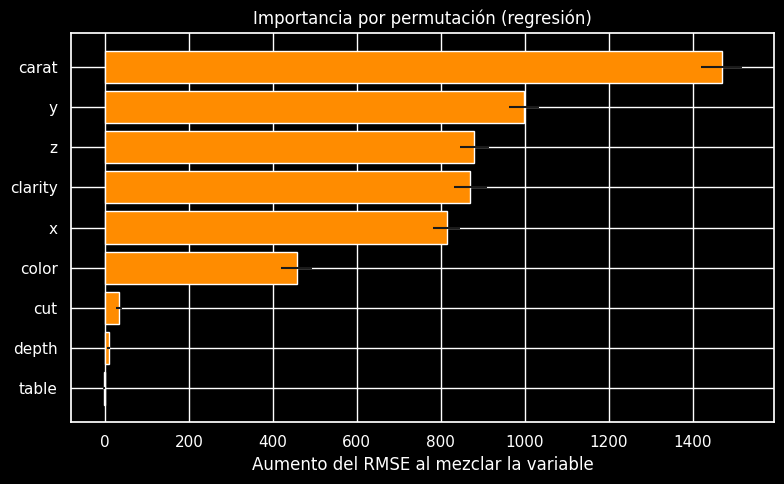

In [28]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Calculamos la importancia por permutación usando X_prueba e y_prueba
imp = permutation_importance(
    mejor_reg,
    X_prueba,
    y_prueba,
    n_repeats=20,
    scoring="neg_root_mean_squared_error",
    random_state=SEMILLA,
    n_jobs=-1
)

#procesamiento de pipeline
importancias = pd.DataFrame({
    "variable": X_prueba.columns,
    "aumento_RMSE": imp.importances_mean,  # cuánto empeora el RMSE al mezclar la variable
    "desvio": imp.importances_std
}).sort_values("aumento_RMSE", ascending=True)

# Graficamos
plt.figure(figsize=(8, 5))
plt.barh(importancias["variable"], importancias["aumento_RMSE"], xerr=importancias["desvio"], color='darkorange')
plt.xlabel("Aumento del RMSE al mezclar la variable")
plt.title("Importancia por permutación (regresión)")
plt.tight_layout()
plt.show()

**Tu respuesta (1.6):**

*(escribí acá tus conclusiones)*

el atributo llamado "carat" , que sería , peso del diamante, se convierte en el atributo mas relevante.

**1.7 · Desafío extra: el precio en escala logarítmica.**

El precio de los diamantes es muy asimétrico (muchos baratos, pocos carísimos). Una técnica habitual es **predecir el logaritmo del precio** y luego volver a la escala original. En `scikit-learn` esto se hace fácil con `TransformedTargetRegressor`:

```python
from sklearn.compose import TransformedTargetRegressor

modelo_log = TransformedTargetRegressor(
    regressor=tu_pipeline_con_mlp,   # el Pipeline que ya armaste
    func=np.log1p,                   # transforma y antes de entrenar
    inverse_func=np.expm1            # revierte la transformación al predecir
)
```

Entrená este modelo, evaluá en prueba y compará con el anterior. ¿Mejoró? ¿Por qué creés que pasa esto?

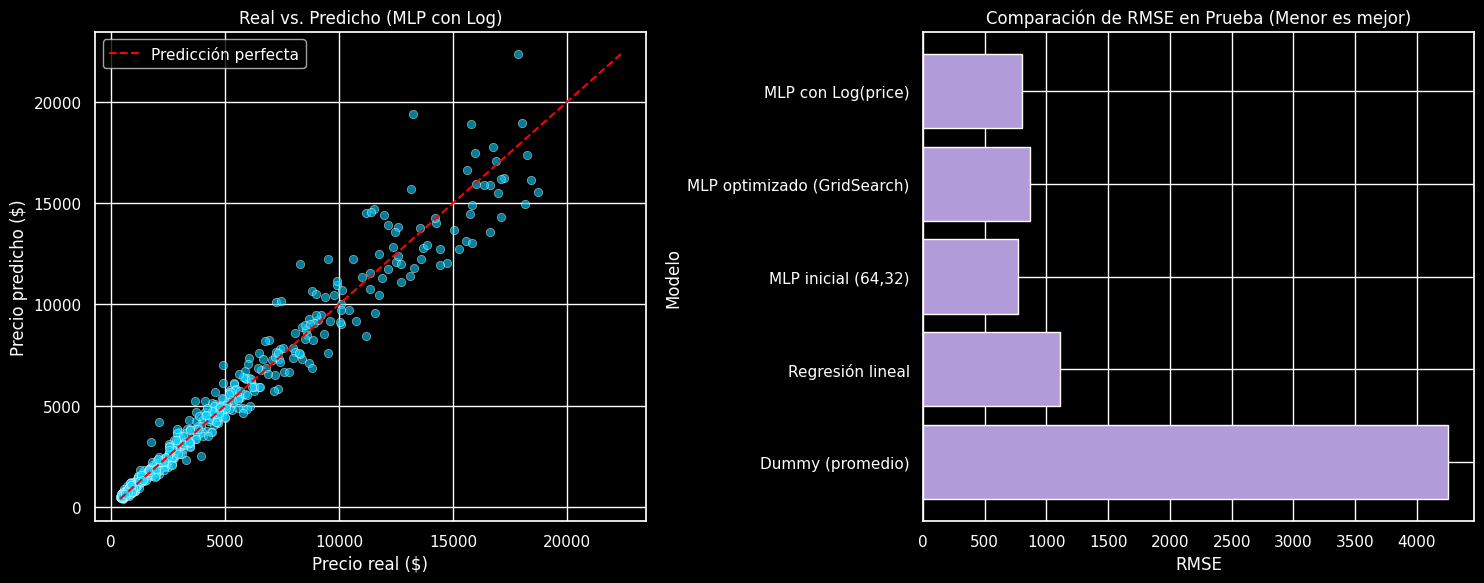

,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
modelo,,,,
Dummy (promedio),4040.451,4249.481,3220.319,-0.001
Regresión lineal,1138.336,1106.483,730.659,0.932
"MLP inicial (64,32)",744.876,768.426,394.444,0.967
MLP optimizado (GridSearch),833.888,864.666,501.093,0.959
MLP con Log(price),821.743,798.858,429.612,0.965


In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import TransformedTargetRegressor

# Activar modo oscuro para los gráficos
plt.style.use('dark_background')

# 1. Creamos y entrenamos el modelo con escala logarítmica
modelo_log = TransformedTargetRegressor(
    regressor=mlp_reg,             # Tu pipeline con el MLP
    func=np.log1p,                 # Transforma 'price' con logaritmo antes de entrenar
    inverse_func=np.expm1          # Revierte la transformación al predecir
)

modelo_log.fit(X_ent, y_ent)

# 2. Evaluamos y guardamos en la lista de resultados
resultados_reg.append(evaluar_regresion(modelo_log, X_ent, y_ent, X_prueba, y_prueba, "MLP con Log(price)"))

# 3. Obtenemos las predicciones para el gráfico
y_pred_log = modelo_log.predict(X_prueba)

# 4. Creamos la figura con los dos gráficos
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Gráfico 1: Real vs. Predicho (Modelo Log) ---
sns.scatterplot(x=y_prueba, y=y_pred_log, ax=axes[0], alpha=0.6, color='#00d2ff')
lims = [min(min(y_prueba), min(y_pred_log)), max(max(y_prueba), max(y_pred_log))]
axes[0].plot(lims, lims, '--', color='red', label='Predicción perfecta')
axes[0].set_title('Real vs. Predicho (MLP con Log)', color='white')
axes[0].set_xlabel('Precio real ($)', color='white')
axes[0].set_ylabel('Precio predicho ($)', color='white')
axes[0].legend()

# --- Gráfico 2: Comparación visual del RMSE de prueba ---
df_res = pd.DataFrame(resultados_reg).set_index("modelo")
axes[1].barh(df_res.index, df_res['RMSE_prueba'], color='#b19cd9')
axes[1].set_title('Comparación de RMSE en Prueba (Menor es mejor)', color='white')
axes[1].set_xlabel('RMSE', color='white')
axes[1].set_ylabel('Modelo', color='white')

plt.tight_layout()
plt.show()

# 5. Mostramos la tabla final actualizada
display(df_res)

In [30]:
# Tu código aquí

**Tu respuesta (1.7):**

*(escribí acá tus conclusiones)*

el logaritmo aplasta los numeros grandes y hace crecer un poco los valores mas pequeños, trayendo un poco de "suavidad" a los datos. esa suavidad se traduce en mayor fluidez para aprender. baja el rmse en en train, osea que aprendiendo,ya mejoró y aumenta el r2

---
## Actividad 4 · reflexión final 💭

Respondé brevemente (2-4 líneas cada una) con tus propias palabras:

1. ¿Por qué es **obligatorio** escalar las variables antes de entrenar una red neuronal? ¿Qué observaste en la demostración?
2. ¿Por qué ajustamos hiperparámetros con **validación cruzada sobre el entrenamiento** y no directamente mirando el conjunto de prueba?
3. En el Paso 6 vimos que distintas semillas dan resultados distintos. ¿Cómo influye esto en la forma en que deberíamos **reportar** el rendimiento de una red neuronal?

**Tus respuestas:**

1.Las redes neuronales son muy sensibles a la escala, cuando los valores son muy extremos, aprende mal y que puede dar valores totalmente erróneos como r2 negativos.

2.porque necesitamos tener los hiperparametros configurados de manera correcta antes del test.

3.o consensuar la semilla, o probar con varias semillas, y promediar resultados, antes el hecho de haber obtenido una semilla de la suerte. un objetivo, es asegurar la reproducibilidad.


---
# 🏁 ¡Felicitaciones!

Completaste una introducción completa al uso de redes neuronales en `scikit-learn`. Recordá la idea central:

> **Una red neuronal no es magia: es un modelo más que hay que preparar bien, evaluar con honestidad y comparar contra alternativas simples.**

 📚 Para seguir explorando
- Documentación de redes neuronales en scikit-learn: <https://scikit-learn.org/stable/modules/neural_networks_supervised.html>
- Guía de validación cruzada: <https://scikit-learn.org/stable/modules/cross_validation.html>
- Ajuste de hiperparámetros: <https://scikit-learn.org/stable/modules/grid_search.html>
- Importancia por permutación: <https://scikit-learn.org/stable/modules/permutation_importance.html>
- Datasets usados: [Auto MPG (UCI)](https://archive.ics.uci.edu/dataset/9/auto+mpg), [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/), y los datasets de ejemplo de [seaborn-data](https://github.com/mwaskom/seaborn-data).